# 04 · Análises: perguntas 2 a 5

- **Dados:** o BERTimbau v3 aplicado às 1,12 milhão de sentenças (`scripts/inferencia.py`). As tabelas são geradas por `scripts/resultados.py`.
- **Correção:** as proporções são corrigidas pela **precisão ponderada por sexo**, P(verdadeiro | previsto) estimada no teste fixo com os pesos de amostragem.
- **Intervalos:** os IC de 95% vêm de um bootstrap que reamostra as pessoas e o teste ao mesmo tempo.
- **Unidade:** a **pessoa**. Cada biografia pesa igual: é a média da fração das suas sentenças com o rótulo.

> Os rótulos de referência são de um LLM, sem validação humana. O gênero é dedutível do texto mascarado (AUC 0,80). FAM_ID é raro e tem F1 de 0,63 [0,29–0,86] no teste.

In [1]:
import json
import pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
F_COR, M_COR = '#b5367a', '#3b6fb6'
R = '../data/resultados/'
ler = lambda n: pd.read_csv(R + n + '.csv')
print(json.load(open(R + 'resumo.json')))

{'pessoas': 45381, 'F': 9276, 'M': 36105, 'bootstrap_replicas': 300, 'metodo_principal': 'precisao ponderada por sexo', 'unidade_principal': 'pessoa'}


In [2]:
def barras_fm(df, cat, titulo, ylabel='% das sentenças (média por pessoa)', ax=None):
    piv = df.pivot_table(index=cat, columns='sexo', values='%', observed=True)
    lo = df.pivot_table(index=cat, columns='sexo', values='IC95_inf', observed=True)
    hi = df.pivot_table(index=cat, columns='sexo', values='IC95_sup', observed=True)
    ax = ax or plt.subplots(figsize=(8, 3.6))[1]
    x = range(len(piv))
    for k, (s, cor) in enumerate([('F', F_COR), ('M', M_COR)]):
        if s not in piv: continue
        xs = [i + (k - .5) * .38 for i in x]
        ax.bar(xs, piv[s], width=.38, color=cor, label=s)
        ax.errorbar(xs, piv[s], yerr=[piv[s] - lo[s], hi[s] - piv[s]], fmt='none', ecolor='black', lw=.8, capsize=2)
    ax.set_xticks(list(x), piv.index, rotation=30, ha='right'); ax.set_ylabel(ylabel); ax.set_title(titulo); ax.legend(frameon=False)
    return ax

## Visão geral: composição do lead e do corpo

In [3]:
g = ler('geral_por_sexo')
g.pivot_table(index=['parte', 'rotulo'], columns='sexo', values='%').round(2)

sexo                F      M
parte rotulo                
corpo APAR       0.16   0.01
      CAR       65.77  68.80
      FAM_CAP    1.12   0.92
      FAM_DET    2.90   2.48
      FAM_ID     0.45   0.13
      FAM_ORIG   1.94   1.97
      GEN        0.76   0.02
      OUTRO     26.90  25.67
lead  APAR       0.13   0.01
      CAR       87.13  87.41
      FAM_CAP    1.17   0.96
      FAM_DET    0.76   1.30
      FAM_ID     0.68   0.29
      FAM_ORIG   0.49   0.98
      GEN        1.69   0.02
      OUTRO      7.95   9.03
total APAR       0.15   0.01
      CAR       71.21  73.90
      FAM_CAP    1.19   1.03
      FAM_DET    2.43   2.37
      FAM_ID     0.53   0.20
      FAM_ORIG   1.57   1.91
      GEN        0.95   0.02
      OUTRO     21.96  20.56

## Pergunta 2: identidade emprestada (FAM_ID)

Fração das sentenças do lead em que a pessoa é apresentada **por um parente**.

In [4]:
display(ler('q2_famid_dif_fm'))
display(ler('q2_famid_lead_sem_stubs'))
display(ler('q2_pessoas_com_famid_lead'))
ler('q2_famid_lead_sensibilidade_metodo')

,F,M,dif F−M (p.p.),IC95_inf,IC95_sup,parte
0,9276,36105,0.38,0.15,0.67,lead
1,9276,36105,0.33,0.14,0.59,total


,F,M,dif F−M (p.p.),IC95_inf,IC95_sup,filtro
0,7307,26833,0.4,0.16,0.69,sem stubs


,sexo,"% pessoas com FAM_ID (lead, bruto)",pessoas
0,F,2.30,9276
1,M,1.14,36105


,F,M,dif F−M (p.p.),IC95_inf,IC95_sup,metodo
0,9276,36105,0.37,0.27,0.48,nenhuma
1,9276,36105,0.38,0.15,0.67,precisao
2,9276,36105,-0.23,-0.32,1.21,acc


,area,F,M,dif F−M (p.p.),IC95_inf,IC95_sup
0,artes_visuais,558,1975,-0.06,-0.35,0.35
1,atuacao_tv,1972,1676,-0.04,-0.35,0.30
2,ciencia_academia,902,2911,0.26,-0.01,0.61
3,esporte,1653,7143,0.00,-0.15,0.21
4,jornalismo_comunicacao,593,1352,0.01,-0.27,0.32
5,literatura,684,1814,0.35,0.04,0.72
6,musica,926,2896,0.07,-0.24,0.39
7,outros,219,781,0.59,0.05,1.32
8,politica,1170,11629,1.77,1.05,2.52
9,religiao,80,1282,0.24,-0.01,0.79


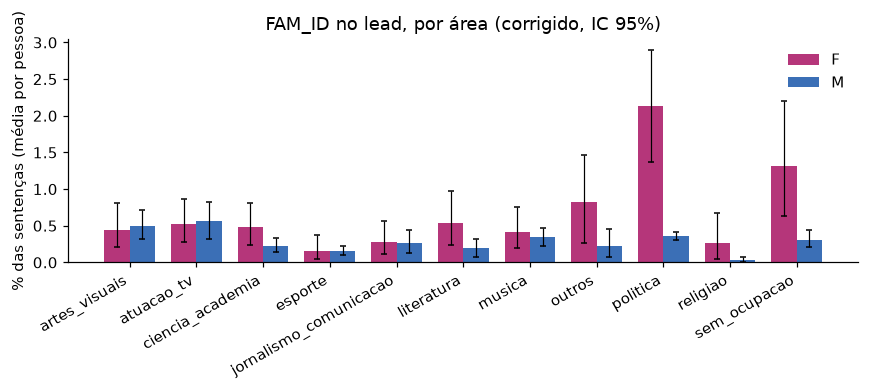

In [5]:
d = ler('q2_famid_lead_por_area')
barras_fm(d, 'area', 'FAM_ID no lead, por área (corrigido, IC 95%)')
plt.tight_layout()
ler('q2_famid_lead_dif_por_area')

## Pergunta 3: marcação de gênero (GEN)

,F,M,dif F−M (p.p.),IC95_inf,IC95_sup
0,9276,36105,1.68,0.98,2.55


,periodo_nasc,sexo,rotulo,pessoas,%,IC95_inf,IC95_sup,% bruto
0,até 1899,F,GEN,385,1.72,0.98,2.79,2.55
1,até 1899,M,GEN,5987,0.02,0.01,0.03,0.02
2,1900–49,F,GEN,2165,1.13,0.68,1.75,1.60
3,1900–49,M,GEN,11544,0.02,0.01,0.03,0.02
4,1950–79,F,GEN,3095,0.81,0.48,1.29,1.07
5,1950–79,M,GEN,9832,0.02,0.01,0.02,0.02
6,1980+,F,GEN,2718,0.81,0.45,1.25,1.06
7,1980+,M,GEN,5297,0.02,0.01,0.04,0.02


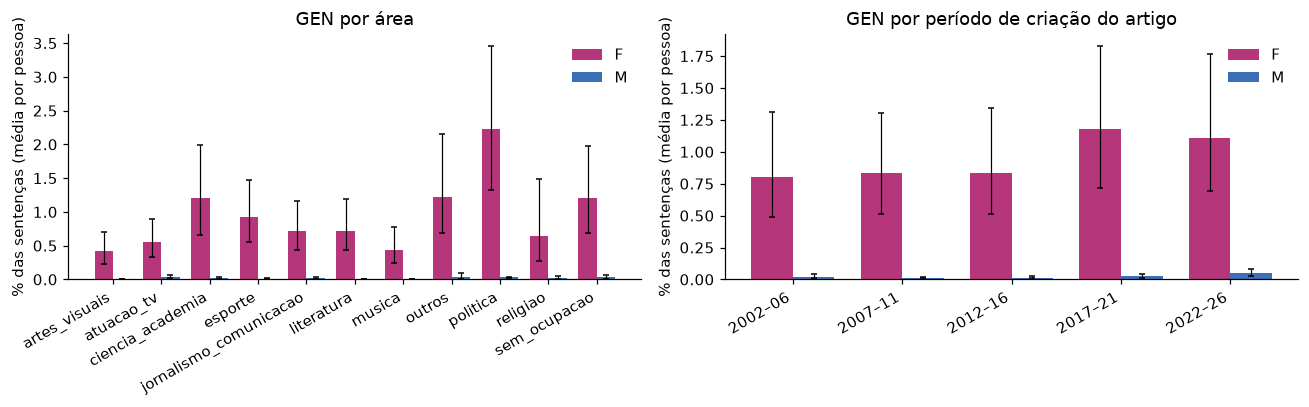

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
barras_fm(ler('q3_gen_por_area'), 'area', 'GEN por área', ax=axs[0])
barras_fm(ler('q3_gen_por_criacao'), 'periodo_criacao', 'GEN por período de criação do artigo', ax=axs[1])
plt.tight_layout()
display(ler('q3_gen_lead_dif_fm'))
ler('q3_gen_por_nascimento')

## Pergunta 4: família como capital (FAM_CAP) em política

In [7]:
display(ler('q4_politica_familia').pivot_table(index=['parte', 'rotulo'], columns='sexo', values=['%', 'IC95_inf', 'IC95_sup']).round(2))
display(ler('q4_politica_famcap_dif_fm'))
ler('q4_famcap_dif_por_area')

%       IC95_inf       IC95_sup      
sexo               F     M        F     M        F     M
parte rotulo                                            
lead  FAM_CAP   1.38  1.14     0.85  0.75     1.97  1.64
      FAM_DET   1.03  1.87     0.52  1.42     1.57  2.37
      FAM_ID    2.13  0.36     1.50  0.30     2.90  0.41
      FAM_ORIG  0.45  1.60     0.25  1.32     0.70  1.95
total FAM_CAP   1.48  1.55     1.08  1.02     2.00  2.17
      FAM_DET   2.01  3.17     1.06  2.54     2.83  3.88
      FAM_ID    1.47  0.31     1.07  0.27     1.91  0.35
      FAM_ORIG  2.16  3.28     1.78  2.75     2.61  3.86

,F,M,dif F−M (p.p.),IC95_inf,IC95_sup
0,1170,11629,-0.07,-0.86,0.66


,area,F,M,dif F−M (p.p.),IC95_inf,IC95_sup
0,artes_visuais,558,1975,0.19,-0.26,0.63
1,atuacao_tv,1972,1676,0.50,-0.08,1.01
2,ciencia_academia,902,2911,-0.07,-0.48,0.36
3,esporte,1653,7143,0.18,-0.09,0.47
4,jornalismo_comunicacao,593,1352,0.10,-0.41,0.53
5,literatura,684,1814,0.68,0.15,1.23
6,musica,926,2896,0.50,-0.08,0.99
7,outros,219,781,0.31,-0.59,0.93
8,politica,1170,11629,-0.07,-0.89,0.67
9,religiao,80,1282,0.86,0.09,1.77


## Pergunta 5: os artigos recentes são escritos de outro jeito?

,periodo_criacao,F,M,dif F−M (p.p.),IC95_inf,IC95_sup
0,2002–06,1468,5770,0.29,-0.03,0.66
1,2007–11,2352,15063,0.71,0.37,1.13
2,2012–16,1818,6474,0.32,0.08,0.64
3,2017–21,1821,5961,0.27,0.08,0.54
4,2022–26,1817,2837,0.40,0.16,0.72


,periodo_criacao,F,M,dif F−M (p.p.),IC95_inf,IC95_sup
0,2002–06,1468,5770,1.32,-0.73,3.16
1,2007–11,2352,15063,0.16,-1.15,1.50
2,2012–16,1818,6474,0.23,-0.77,1.24
3,2017–21,1821,5961,-0.48,-1.29,0.38
4,2022–26,1817,2837,0.05,-0.84,0.76


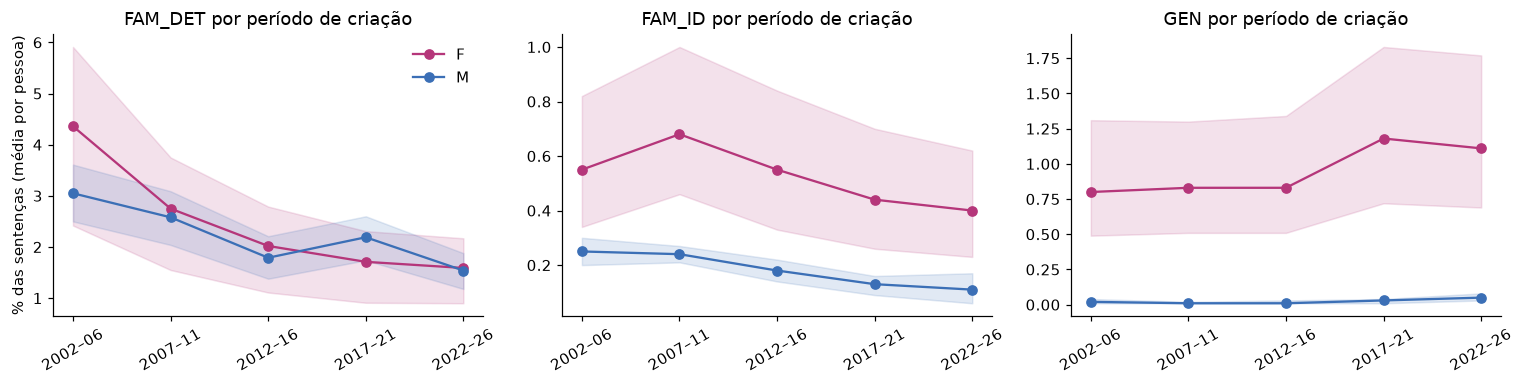

In [8]:
t = ler('q5_por_criacao_total')
fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, rot in zip(axs, ['FAM_DET', 'FAM_ID', 'GEN']):
    for s, cor in [('F', F_COR), ('M', M_COR)]:
        x = t[(t.rotulo == rot) & (t.sexo == s)]
        ax.plot(x.periodo_criacao, x['%'], marker='o', color=cor, label=s)
        ax.fill_between(x.periodo_criacao, x.IC95_inf, x.IC95_sup, color=cor, alpha=.15)
    ax.set_title(f'{rot} por período de criação'); ax.tick_params(axis='x', rotation=30)
axs[0].set_ylabel('% das sentenças (média por pessoa)'); axs[0].legend(frameon=False)
plt.tight_layout()
display(ler('q5_famid_lead_dif_por_criacao'))
ler('q5_famdet_dif_por_criacao')

## Exemplos de leads

Primeiras sentenças com o rótulo previsto, com probabilidade acima de 0,8, cortadas em 220 caracteres.

In [9]:
pd.set_option('display.max_colwidth', 230)
ler('exemplos_leads')

,titulo,sexo,area,texto,rotulo
0,Maria Thereza Goulart,F,politica,"Durante a presidência do marido, assumiu a presidência de honra da Legião Brasileira de Assistência (LBA), na qual participou da organização da representação da entidade em Brasília e de iniciativas relacionadas à saúde",FAM_ID
1,Dulce Figueiredo,F,politica,"Dulce Maria de Castro Figueiredo GCIH (Rio de Janeiro, 11 de maio de 1923 — Rio de Janeiro, 6 de junho de 2011) foi a primeira-dama do país entre 15 de março de 1979 e 15 de março de 1985, durante a presidência de seu ma",FAM_ID
2,Juana Elbein dos Santos,F,ciencia_academia,Foi esposa de Mestre Didi por meio século.,FAM_ID
3,Rosângela Lula da Silva,F,politica,"Como primeira-dama, passou a atuar em agendas relacionadas ao enfrentamento da fome e da pobreza, aos direitos das mulheres, à proteção da infância, à vacinação, à cultura, à inclusão social, à sustentabilidade ambiental",FAM_ID
4,Deuzeni Goldman,F,sem_ocupacao,"É viúva do 59.º governador de São Paulo, Alberto Goldman, atuando como primeira-dama do estado paulista entre abril de 2010 e janeiro de 2011.",FAM_ID
5,Saudade Braga,F,politica,Era mãe do deputado federal Glauber Braga.,FAM_ID
6,Jerônimo José de Viveiros,M,politica,"Foi pai de Francisco Mariano de Viveiros Sobrinho, o Barão de São Bento.",FAM_ID
7,Azevedo Lima,M,sem_ocupacao,Pai do também médico e político brasileiro João Batista de Azevedo Lima.,FAM_ID
8,José Vecchio,M,politica,"José Vecchio foi pai de Miguelina Vecchio, atual Vice-Presidente Nacional do PDT e Presidente Nacional da Ação da Mulher Trabalhista (AMT).",FAM_ID
9,Luiz Sergio Person,M,artes_visuais,É pai das apresentadoras e atrizes Marina Person e Domingas Person.,FAM_ID
